# 02 - Hedge ratios and position sizing

**Main case:** long NVDA, short QQQ. **Other hedges:** SMH, SOXX, XLK, SPY, and four
equal-weight stock baskets rebalanced monthly (`semis_ex_nvda`, `hyperscalers`,
`ai_infra`, `broad_ai`; definitions in `config/settings.toml`).

Part A estimates hedge ratios: how many dollars of the hedge to short per dollar of
NVDA, and how much risk that removes, in sample and out of sample.
Part B sizes the book so its 1-day 99% VaR is \$10,000, then works out margin,
capital and carry.

**Conventions**
- Returns are daily total returns (dividends included) from `load.returns()`: CRSP
  through 2025, yfinance for 2026. "Excess" means over the 3-month T-bill.
- Hedge ratio `h` = dollars short per dollar long, so `S = h * L`.
- The hedged book's daily return per \$1 of NVDA, net of financing and borrow, is

  `u = (r_NVDA - rf) - h * (r_H - rf) - h * fee / 252`

  The long is financed at rf. The short pays the hedge's total return (price move plus
  dividends owed to the lender), earns the rebate `rf - fee` on the proceeds, and
  `fee` is Markit's indicative borrow fee. So dividends and carry are already in `u`.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

from nvai import hedge as hg
from nvai.config import FIGURES, settings
from nvai.data import load

pd.set_option("display.width", 170, "display.max_columns", 30,
              "display.float_format", lambda v: f"{v:,.3f}")
S_ = settings()
TARGET = S_["universe"]["target"]
VAR_TARGET = 10_000           # $ 1-day 99% VaR budget
ANN = 252

ETF_HEDGES = ["QQQ", "SMH", "SOXX", "XLK", "SPY"]
BASKETS = {k: S_["baskets"][k] for k in ["semis_ex_nvda", "hyperscalers", "ai_infra",
                                         "broad_ai"]}
HEDGES = ETF_HEDGES + list(BASKETS)

# Styling as in 01: recessive axes, thin lines, one fixed color per hedge.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6",
           "#e34948"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "lines.linewidth": 1.5, "legend.frameon": False, "font.size": 9,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
COLOR = dict(zip(HEDGES, PALETTE + [INK2]))   # 9 hedges: 8 palette slots + gray for broad_ai


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")
    plt.show()

## 1. Data: hedge return series, excess returns, borrow fees, dividend yields

In [2]:
ret = load.returns()
rf = load.risk_free().reindex(ret.index).ffill()
fees = load.borrow_fees(fill_default=True).reindex(ret.index).ffill()

# One return series per hedge: ETFs directly, baskets equal-weight monthly.
H = pd.DataFrame({e: ret[e] for e in ETF_HEDGES})
for name, names in BASKETS.items():
    H[name] = hg.ew_monthly_basket(ret[names])
H = H.dropna(how="all")
nv = ret[TARGET].reindex(H.index)
rf = rf.reindex(H.index)

xs_nv = nv - rf
xs_H = H.sub(rf, axis=0)

# Borrow fee per hedge (annualized decimal): Markit for ETFs; for a basket, the average
# of its names' fees, since each name is shorted with weight 1/n.
FEE = pd.DataFrame({e: fees[e] for e in ETF_HEDGES}, index=H.index)
for name, names in BASKETS.items():
    FEE[name] = fees[names].reindex(H.index).mean(axis=1)

print(f"sample {H.index.min().date()} to {H.index.max().date()}, {len(H)} days")
print("latest borrow fee, 21-day mean (bp):")
(1e4 * FEE.tail(21).mean()).round(0).to_frame("fee_bp").T

sample 2019-01-02 to 2026-11-20, 1984 days
latest borrow fee, 21-day mean (bp):


,QQQ,SMH,SOXX,XLK,SPY,semis_ex_nvda,hyperscalers,ai_infra,broad_ai
fee_bp,35.000,68.000,75.000,33.000,34.000,30.000,30.000,31.000,31.000


Dividend yields (trailing 12 months of dividends over the latest price, yfinance).
They matter for carry: the long receives NVDA's dividend, and the short owes the
hedge's dividend to the stock lender.

In [3]:
yfr = pd.read_parquet(load.raw_dir("free") / "yfinance.parquet")
last_day = yfr.date.max()
yr = yfr[yfr.date > last_day - pd.DateOffset(years=1)]
dy = (yr.groupby("ticker").dividends.sum()
      / yfr.sort_values("date").groupby("ticker").close.last())
DY = {TARGET: dy[TARGET], **{e: dy[e] for e in ETF_HEDGES},
      **{k: dy[v].mean() for k, v in BASKETS.items()}}
pd.Series(DY).mul(100).round(2).to_frame("div yield %").T

,NVDA,QQQ,SMH,SOXX,XLK,SPY,semis_ex_nvda,hyperscalers,ai_infra,broad_ai
div yield %,0.410,0.510,0.280,0.340,0.560,1.100,0.610,0.690,0.420,0.550


## A1. Full-sample OLS hedge ratios

Regress NVDA's daily excess return on each hedge's excess return:
`xs_NVDA = a + beta * xs_H + e`. Here `beta` is the variance-minimizing hedge ratio,
R² is the share of NVDA's variance the hedge removes, and `vol(e)` is the
idiosyncratic risk left after hedging. Standard errors are Newey-West with 5 lags.

The same regression on **weekly** returns checks for asynchronous trading. ADRs like
TSM and ASML trade in New York, but their home markets close hours earlier, and the
baskets mix in names whose news arrives at different times. That biases daily betas
down, and weekly betas largely undo it.

In [4]:
def ols(y, x):
    d = pd.concat([y, x], axis=1).dropna()
    m = sm.OLS(d.iloc[:, 0], sm.add_constant(d.iloc[:, 1])).fit(
        cov_type="HAC", cov_kwds={"maxlags": 5})
    return m, d


def weekly(s):
    return (1 + s).resample("W-FRI").prod() - 1


rows = []
xs_nv_w = weekly(nv) - weekly(rf)
for h in HEDGES:
    m, d = ols(xs_nv, xs_H[h])
    mw, dw = ols(xs_nv_w, weekly(H[h]) - weekly(rf))
    rows.append({
        "hedge": h, "beta": m.params.iloc[1], "beta_se": m.bse.iloc[1], "R2": m.rsquared,
        "corr": d.corr().iloc[0, 1],
        "alpha_ann_%": 100 * ANN * m.params.iloc[0],
        "nvda_vol_%": 100 * d.iloc[:, 0].std() * np.sqrt(ANN),
        "resid_vol_%": 100 * m.resid.std() * np.sqrt(ANN),
        "beta_weekly": mw.params.iloc[1], "R2_weekly": mw.rsquared,
    })
A1 = pd.DataFrame(rows).set_index("hedge")
A1["var_reduction_%"] = 100 * A1["R2"]
A1.round(3)

,beta,beta_se,R2,corr,alpha_ann_%,nvda_vol_%,resid_vol_%,beta_weekly,R2_weekly,var_reduction_%
hedge,,,,,,,,,,
QQQ,1.660,0.043,0.624,0.790,26.032,50.629,31.056,1.651,0.601,62.373
SMH,1.148,0.031,0.693,0.832,18.579,50.629,28.073,1.144,0.659,69.254
SOXX,1.030,0.036,0.609,0.780,24.974,50.629,31.665,1.038,0.580,60.883
XLK,1.490,0.045,0.640,0.800,23.823,50.629,30.390,1.481,0.609,63.970
SPY,1.834,0.079,0.487,0.698,31.573,50.629,36.262,1.706,0.447,48.701
semis_ex_nvda,0.958,0.037,0.563,0.750,20.850,50.629,33.461,0.933,0.523,56.320
hyperscalers,1.237,0.043,0.450,0.671,30.396,50.629,37.554,1.163,0.396,44.981
ai_infra,0.934,0.034,0.550,0.742,13.920,50.629,33.963,0.878,0.530,54.999
broad_ai,1.187,0.036,0.617,0.785,14.582,50.629,31.343,1.142,0.584,61.674


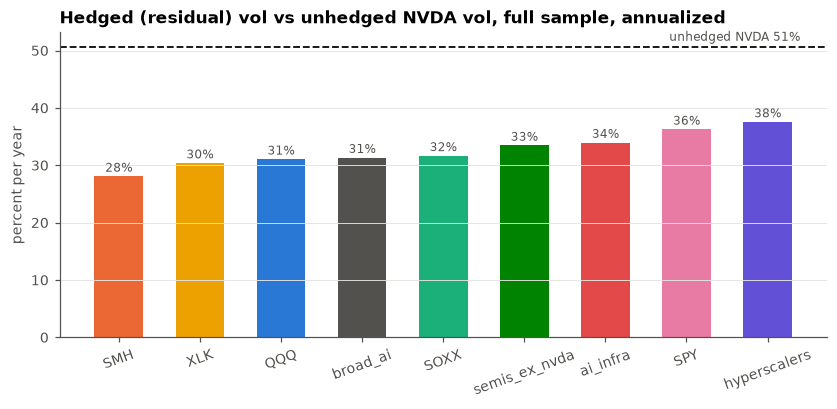

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
order = A1.sort_values("resid_vol_%").index
ax.bar(order, A1.loc[order, "resid_vol_%"], color=[COLOR[h] for h in order], width=0.6)
ax.axhline(A1["nvda_vol_%"].iat[0], color=INK, lw=1.2, ls="--")
ax.annotate(f"unhedged NVDA {A1['nvda_vol_%'].iat[0]:.0f}%", (len(order) - 0.6,
            A1["nvda_vol_%"].iat[0]), xytext=(0, 4), textcoords="offset points",
            ha="right", fontsize=8, color=INK2)
for i, h in enumerate(order):
    ax.annotate(f"{A1.loc[h, 'resid_vol_%']:.0f}%", (i, A1.loc[h, "resid_vol_%"]),
                xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8,
                color=INK2)
ax.set_title("Hedged (residual) vol vs unhedged NVDA vol, full sample, annualized")
ax.set_ylabel("percent per year")
ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", rotation=20)
save(fig, "02_hedged_vs_unhedged_vol")

## A2. Betas move a lot: rolling 63-day and 252-day betas

Each panel shows one hedge, with the 63-day beta (thin) and the 252-day beta (thick).
The full-sample beta is the dashed line.

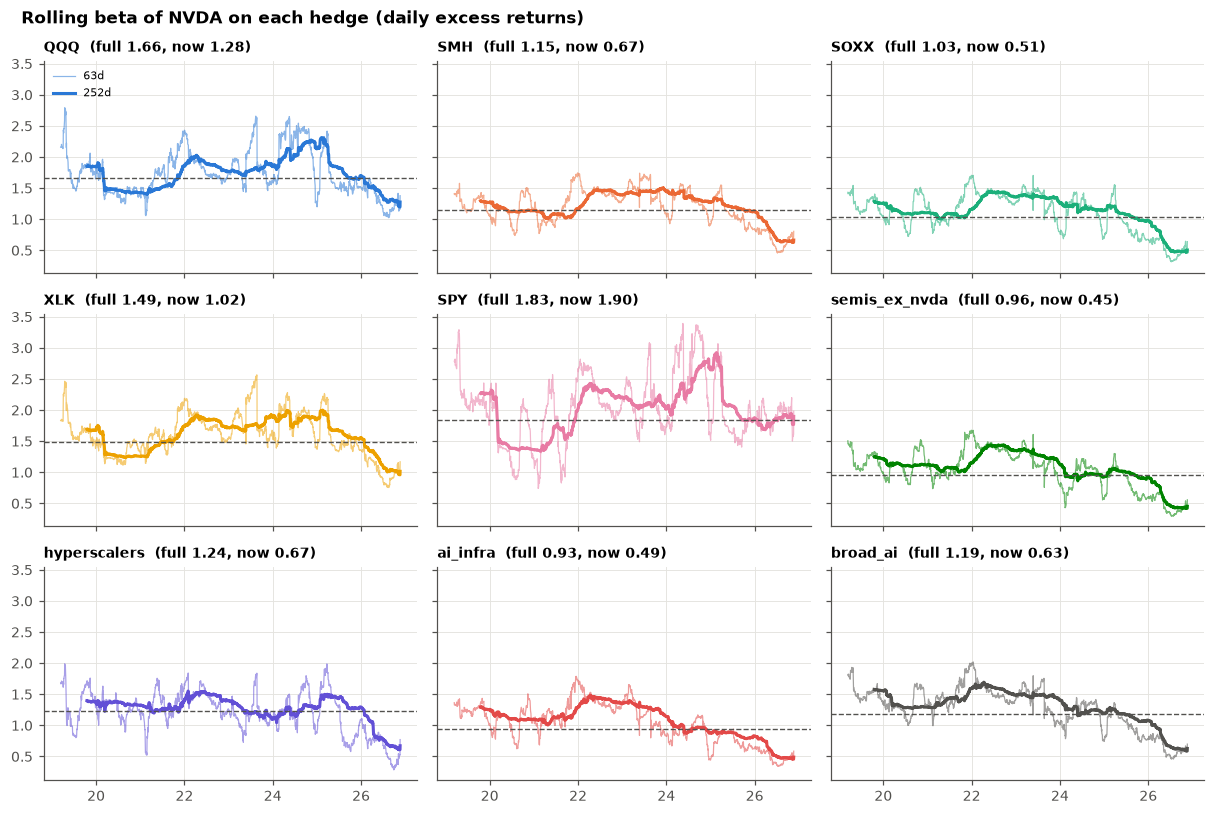

In [6]:
beta63 = pd.DataFrame({h: hg.rolling_beta(xs_nv, xs_H[h], 63) for h in HEDGES})
beta252 = pd.DataFrame({h: hg.rolling_beta(xs_nv, xs_H[h], 252) for h in HEDGES})

fig, axes = plt.subplots(3, 3, figsize=(11, 7.5), sharex=True, sharey=True)
for ax, h in zip(axes.flat, HEDGES):
    ax.plot(beta63.index, beta63[h], color=COLOR[h], lw=0.8, alpha=0.55, label="63d")
    ax.plot(beta252.index, beta252[h], color=COLOR[h], lw=2, label="252d")
    ax.axhline(A1.loc[h, "beta"], color=INK2, lw=0.9, ls="--")
    ax.set_title(f"{h}  (full {A1.loc[h, 'beta']:.2f}, now {beta252[h].dropna().iat[-1]:.2f})",
                 fontsize=9)
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%y"))
axes.flat[0].legend(loc="upper left", fontsize=7)
fig.suptitle("Rolling beta of NVDA on each hedge (daily excess returns)", x=0.01,
             ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "02_rolling_betas")

**QQQ in detail: 63d, 252d and EWMA beta.** The EWMA beta uses a 63-day half-life, so
it weights recent days more without a hard window edge.

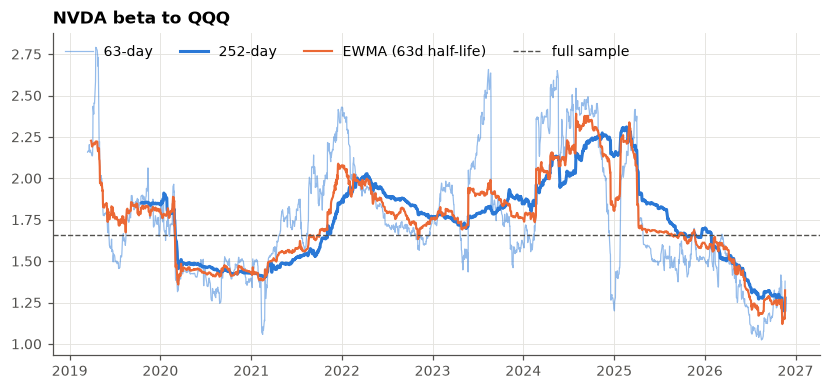

,full sample,252d now,63d now,EWMA now
QQQ beta,1.660,1.276,1.379,1.323


In [7]:
ewma_qqq = hg.ewma_beta(xs_nv, xs_H["QQQ"], halflife=63)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(beta63.index, beta63["QQQ"], color=PALETTE[0], lw=0.8, alpha=0.5, label="63-day")
ax.plot(beta252.index, beta252["QQQ"], color=PALETTE[0], lw=2, label="252-day")
ax.plot(ewma_qqq.index, ewma_qqq, color=PALETTE[1], lw=1.4, label="EWMA (63d half-life)")
ax.axhline(A1.loc["QQQ", "beta"], color=INK2, lw=0.9, ls="--", label="full sample")
ax.set_title("NVDA beta to QQQ")
ax.legend(ncol=4, loc="upper left")
save(fig, "02_qqq_beta_detail")
pd.Series({"full sample": A1.loc["QQQ", "beta"], "252d now": beta252["QQQ"].iat[-1],
           "63d now": beta63["QQQ"].iat[-1], "EWMA now": ewma_qqq.iat[-1]},
          name="QQQ beta").to_frame().T

## A3. Out of sample: estimate on the trailing year, hold for a month

At each month start, estimate on the trailing 252 days known at the prior close,
then hold the ratio fixed for the month. Three rules:
- **beta**: `h` = the trailing OLS beta to the hedge.
- **dollar**: `h = 1` (dollar neutral).
- **minvar**: regress NVDA on the basket's individual names at once and short each
  name by its own coefficient. This is the multi-asset minimum-variance hedge. A single
  ETF has no names to split, and with one instrument the minimum-variance ratio *is*
  the OLS beta, so for ETFs it equals the beta rule.

All rules use the net-of-borrow return `u` defined at the top.

In [8]:
h_beta = beta252.apply(hg.hold_monthly)


def book(h_ratio, hedge):
    """Daily net excess return of long $1 NVDA / short h_ratio of the hedge."""
    return xs_nv - h_ratio * xs_H[hedge] - h_ratio * FEE[hedge] / ANN


def minvar_multi(names):
    """Monthly-refit multi-name minimum-variance hedge on a basket's constituents."""
    X = ret[names].reindex(H.index).sub(rf, axis=0)
    out = pd.Series(np.nan, index=H.index)
    months = H.index.to_period("M")
    for m in months.unique():
        idx = np.where(months == m)[0]
        start = idx[0]
        if start < 252:
            continue
        win = slice(start - 252, start)
        Xw = X.iloc[win].dropna(axis=1)                   # names with a full window
        yw = xs_nv.iloc[win]
        A = np.column_stack([np.ones(len(Xw)), Xw.to_numpy()])
        b = np.linalg.lstsq(A, yw.to_numpy(), rcond=None)[0][1:]
        Xm = X.iloc[idx][Xw.columns].fillna(0)
        f = fees[Xw.columns].reindex(H.index).iloc[idx].to_numpy()
        cost = (np.clip(b, 0, None) * f).sum(axis=1) / ANN   # borrow fee only on shorts
        out.iloc[idx] = xs_nv.iloc[idx].to_numpy() - Xm.to_numpy() @ b - cost
    return out


U = {}   # (hedge, rule) -> daily net excess return of the hedged book
for h in HEDGES:
    U[(h, "beta")] = book(h_beta[h], h)
    U[(h, "dollar")] = book(1.0, h)
    U[(h, "minvar")] = minvar_multi(BASKETS[h]) if h in BASKETS else U[(h, "beta")]
U = pd.DataFrame(U)
oos_start = h_beta.dropna(how="all").index.min()
U = U[U.index >= oos_start]
unhedged = xs_nv[xs_nv.index >= oos_start]

vol_by_year = (U.groupby(U.index.year).std() * np.sqrt(ANN) * 100)
vol_by_year[("NVDA", "unhedged")] = unhedged.groupby(unhedged.index.year).std() \
    * np.sqrt(ANN) * 100
vol_all = U.std() * np.sqrt(ANN) * 100
print(f"out-of-sample period {oos_start.date()} to {U.index.max().date()}")
print("Realized vol of the hedged book by year, % annualized (rule = beta):")
vol_by_year.xs("beta", axis=1, level=1).assign(NVDA=vol_by_year[("NVDA", "unhedged")]
                                                ).round(1)

out-of-sample period 2019-10-01 to 2026-11-20
Realized vol of the hedged book by year, % annualized (rule = beta):


,QQQ,SMH,SOXX,XLK,SPY,semis_ex_nvda,hyperscalers,ai_infra,broad_ai,NVDA
date,,,,,,,,,,
2019,23.300,21.600,21.400,23.500,24.900,22.000,24.700,23.500,21.400,29.600
2020,29.000,28.900,28.900,30.800,39.900,29.900,32.800,35.300,29.600,57.800
2021,29.900,27.900,28.700,30.400,37.100,30.400,37.100,33.400,30.200,45.000
2022,28.000,22.200,22.800,28.700,34.200,25.300,37.000,30.700,26.400,63.200
2023,35.400,27.600,32.500,33.300,40.600,35.500,41.100,33.100,32.500,48.400
2024,36.400,27.900,34.600,33.100,41.300,38.000,44.600,36.300,34.900,52.500
2025,30.500,24.500,30.600,26.100,36.300,30.300,33.800,26.600,26.600,49.600
2026,30.500,30.800,34.200,29.800,31.300,35.100,38.600,33.400,33.000,42.400


In [9]:
oos = vol_all.unstack().reindex(HEDGES)[["beta", "dollar", "minvar"]]
oos["unhedged NVDA"] = unhedged.std() * np.sqrt(ANN) * 100
print("Whole out-of-sample period, % annualized:")
oos.round(1)

Whole out-of-sample period, % annualized:


,beta,dollar,minvar,unhedged NVDA
QQQ,31.300,35.100,31.300,51.300
SMH,27.100,28.800,27.100,51.300
SOXX,30.300,32.200,30.300,51.300
XLK,30.200,33.400,30.200,51.300
SPY,37.100,40.100,37.100,51.300
semis_ex_nvda,32.100,34.100,31.400,51.300
hyperscalers,37.600,38.400,38.200,51.300
ai_infra,32.600,34.600,33.000,51.300
broad_ai,30.300,32.300,30.300,51.300


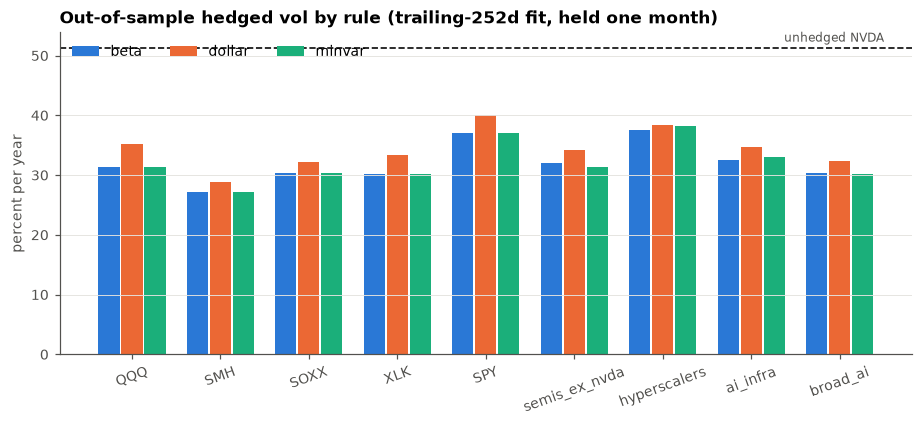

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(HEDGES))
for i, (rule, c) in enumerate(zip(["beta", "dollar", "minvar"], [PALETTE[0], PALETTE[1],
                                                                  PALETTE[2]])):
    ax.bar(x + (i - 1) * 0.26, oos[rule], width=0.24, color=c, label=rule)
ax.axhline(oos["unhedged NVDA"].iat[0], color=INK, ls="--", lw=1.1)
ax.annotate("unhedged NVDA", (len(HEDGES) - 0.5, oos["unhedged NVDA"].iat[0]),
            xytext=(0, 4), textcoords="offset points", ha="right", fontsize=8, color=INK2)
ax.set_xticks(x, HEDGES, rotation=20)
ax.set_ylabel("percent per year")
ax.set_title("Out-of-sample hedged vol by rule (trailing-252d fit, held one month)")
ax.legend(ncol=3, loc="upper left")
ax.grid(axis="x", visible=False)
save(fig, "02_oos_hedged_vol")

## A4. NVDA inside the ETFs mechanically raises the beta

If an ETF holds a weight `w` of NVDA, then `r_ETF = w * r_NVDA + (1 - w) * r_rest`.
Part of NVDA's measured beta to the ETF is NVDA regressed on itself, so the ETF looks
like a better hedge than "the rest of AI" really is. Shorting `h` dollars of the ETF
also shorts `h * w` dollars of NVDA, so the book's net NVDA exposure is `1 - h * w`.

Strip NVDA out with the previous day's ETF Global weight:
`r_ex = (r_ETF - w * r_NVDA) / (1 - w)`. That gives each ETF's "ex-NVDA" version.

In [11]:
w = load.nvda_weight().reindex(H.index).ffill().shift(1)
rows, EX = [], {}
for e in ETF_HEDGES:
    we = w[e]
    ex = (H[e] - we * nv) / (1 - we)
    EX[e] = ex
    m_full, _ = ols(xs_nv, xs_H[e])
    m_ex, _ = ols(xs_nv, ex - rf)
    h_now = beta252[e].iat[-1]
    rows.append({"hedge": e, "NVDA weight avg %": 100 * we.mean(),
                 "NVDA weight now %": 100 * we.dropna().iat[-1],
                 "beta": m_full.params.iloc[1], "beta ex-NVDA": m_ex.params.iloc[1],
                 "R2": m_full.rsquared, "R2 ex-NVDA": m_ex.rsquared,
                 "h now": h_now, "net NVDA exposure now (1-h*w)":
                     1 - h_now * we.dropna().iat[-1]})
A4 = pd.DataFrame(rows).set_index("hedge")
A4["beta from NVDA inside"] = A4["beta"] - A4["beta ex-NVDA"]
A4.round(3)

,NVDA weight avg %,NVDA weight now %,beta,beta ex-NVDA,R2,R2 ex-NVDA,h now,net NVDA exposure now (1-h*w),beta from NVDA inside
hedge,,,,,,,,,
QQQ,4.897,8.012,1.660,1.604,0.624,0.551,1.276,0.898,0.056
SMH,13.549,19.622,1.148,1.046,0.693,0.566,0.666,0.869,0.102
SOXX,8.298,7.648,1.030,0.966,0.609,0.535,0.506,0.961,0.064
XLK,7.318,14.982,1.490,1.423,0.640,0.548,1.016,0.848,0.067
SPY,3.323,7.771,1.834,1.737,0.487,0.419,1.899,0.852,0.096


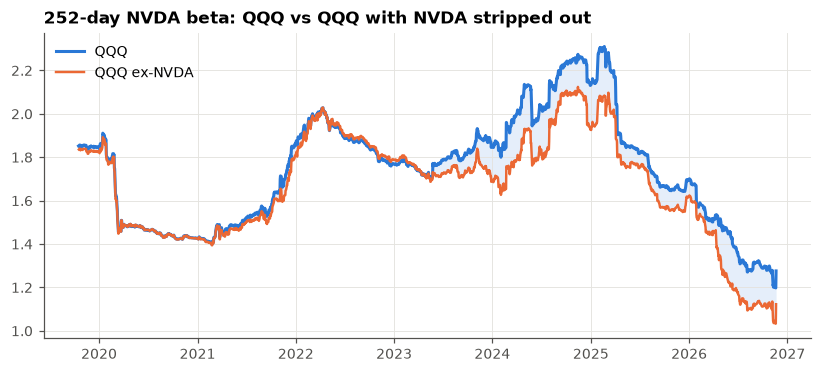

In [12]:
EX = pd.DataFrame(EX)
b_ex = hg.rolling_beta(xs_nv, EX["QQQ"] - rf, 252)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(beta252.index, beta252["QQQ"], color=PALETTE[0], lw=2, label="QQQ")
ax.plot(b_ex.index, b_ex, color=PALETTE[1], lw=1.6, label="QQQ ex-NVDA")
ax.fill_between(b_ex.index, b_ex, beta252["QQQ"], color=PALETTE[0], alpha=0.12, lw=0)
ax.set_title("252-day NVDA beta: QQQ vs QQQ with NVDA stripped out")
ax.legend(loc="upper left")
save(fig, "02_qqq_ex_nvda_beta")

## B1. Sizing long NVDA / short QQQ for a 1-day 99% VaR of \$10,000

`h` is the current trailing-252-day beta. Then the daily P&L is `L * u`, where `u` is
the net book return per \$1 long. The P&L history uses today's `h` on every past day
(the usual "current portfolio, historical scenarios" approach).

Each VaR method gives a loss fraction `v`, and the notional is `L = $10,000 / v`:
- **parametric**: `v = 2.326 * sigma`, with sigma from the trailing 252 days.
- **historical, full**: `v` = minus the 1st percentile of `u`, 2019 to today.
- **historical, 252d**: the same over the trailing 252 days only.
- **EWMA**: `v = 2.326 * sigma_EWMA`, the RiskMetrics forecast (lambda = 0.94) as of
  today.

For each size, the table also shows the 10-day VaR (sqrt(10) scaling and historical
overlapping 10-day sums), 99% expected shortfall, \$ vol, the worst historical day, and
the maximum drawdown of the \$ P&L path at constant notional.

In [13]:
def unit_pnl(hedge, h_now=None):
    h_now = beta252[hedge].dropna().iat[-1] if h_now is None else h_now
    u = (xs_nv - h_now * xs_H[hedge] - h_now * FEE[hedge] / ANN).dropna()
    return u, h_now


def sizing_table(hedge):
    u, h_now = unit_pnl(hedge)
    u252 = u.iloc[-252:]
    sig252 = u252.std()
    sig_ewma = hg.ewma_vol(u).iat[-1]
    v = {"parametric (252d)": hg.Z99 * sig252,
         "historical (full)": hg.hist_var(u),
         "historical (252d)": hg.hist_var(u252),
         "EWMA (lambda 0.94)": hg.Z99 * sig_ewma}
    u10 = u.rolling(10).sum().dropna()                    # overlapping 10-day P&L
    out = []
    for meth, vv in v.items():
        L = VAR_TARGET / vv
        out.append({
            "method": meth, "VaR frac %": 100 * vv, "L": L, "S": h_now * L,
            "gross": (1 + h_now) * L,
            "VaR 1d": VAR_TARGET,
            "VaR 10d sqrt10": VAR_TARGET * np.sqrt(10),
            "VaR 10d hist": L * hg.hist_var(u10),
            "ES 1d (method)": L * (hg.ES99_NORMAL * vv / hg.Z99 if "hist" not in meth
                                   else hg.hist_es(u if "full" in meth else u252)),
            "$ vol daily (252d)": L * sig252,
            "$ vol annual (252d)": L * sig252 * np.sqrt(ANN),
            "worst day": L * u.min(), "worst day date": u.idxmin().date(),
            "max drawdown": L * hg.max_drawdown(u),
        })
    t = pd.DataFrame(out).set_index("method")
    t.attrs["h"] = h_now
    return t


sz_qqq = sizing_table("QQQ")
print(f"QQQ hedge ratio now h = {sz_qqq.attrs['h']:.3f}")
fmt = {c: "{:,.0f}" for c in sz_qqq.columns if c not in ("VaR frac %", "worst day date")}
sz_qqq.style.format(fmt | {"VaR frac %": "{:.2f}"})

QQQ hedge ratio now h = 1.276


,VaR frac %,L,S,gross,VaR 1d,VaR 10d sqrt10,VaR 10d hist,ES 1d (method),$ vol daily (252d),$ vol annual (252d),worst day,worst day date,max drawdown
method,,,,,,,,,,,,,
parametric (252d),4.34,"230,297","293,937","524,234","10,000","31,623","32,091","11,457","4,299","68,238","-30,512",2025-01-27,"104,376"
historical (full),4.60,"217,387","277,459","494,846","10,000","31,623","30,292","14,204","4,058","64,413","-28,802",2025-01-27,"98,525"
historical (252d),5.20,"192,330","245,478","437,808","10,000","31,623","26,801","13,701","3,590","56,988","-25,482",2025-01-27,"87,169"
EWMA (lambda 0.94),6.89,"145,211","185,338","330,549","10,000","31,623","20,235","11,457","2,710","43,027","-19,239",2025-01-27,"65,813"


**Rolling L.** This is the notional that would have kept the 1-day 99% VaR at \$10k
over time. It uses the out-of-sample hedge ratio (trailing beta, held monthly), with
vol from the trailing 252 days or from EWMA. When vol spikes, the book has to shrink.

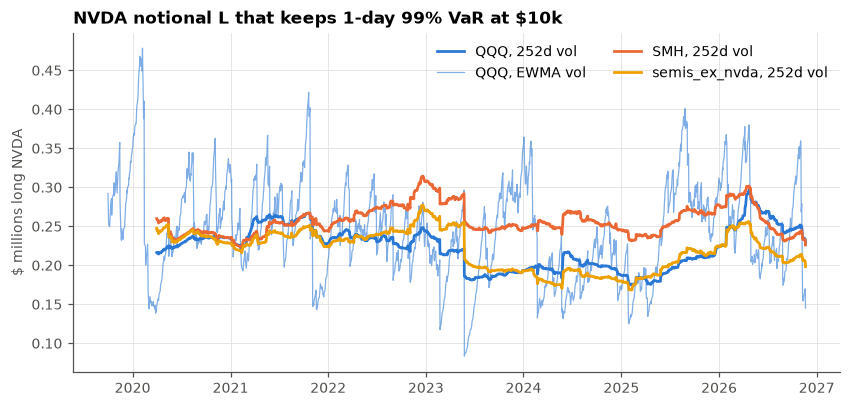

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
for hedge, c in [("QQQ", PALETTE[0]), ("SMH", PALETTE[1]), ("semis_ex_nvda", PALETTE[3])]:
    u_oos = U[(hedge, "beta")].dropna()
    L_roll = VAR_TARGET / (hg.Z99 * u_oos.rolling(252, min_periods=126).std())
    ax.plot(L_roll.index, L_roll / 1e6, color=c, lw=1.8, label=f"{hedge}, 252d vol")
    if hedge == "QQQ":
        L_ew = VAR_TARGET / (hg.Z99 * hg.ewma_vol(u_oos))
        ax.plot(L_ew.index, L_ew / 1e6, color=c, lw=0.8, alpha=0.6, label="QQQ, EWMA vol")
ax.set_title("NVDA notional L that keeps 1-day 99% VaR at $10k")
ax.set_ylabel("$ millions long NVDA")
ax.legend(loc="upper right", ncol=2)
save(fig, "02_rolling_var_notional")

## B2. Margin, capital and where the short proceeds go

Shorting `S` of QQQ raises `S` of cash, but the broker keeps it as collateral for the
borrowed shares. **It cannot be used to buy the NVDA.** Under Reg T:
- **Short:** you must hold 150% of `S` in the short account. The proceeds cover 100%,
  and you post the other 50% from your own equity.
- **Long:** you post 50% of `L` as initial margin and borrow the rest from the broker
  (or pay 100% in a cash account).

So Reg T capital is `0.5 * L + 0.5 * S`. Portfolio margin nets the risk of the two legs.
We use an approximate house rule of 15% per leg, `0.15 * (L + S)`; real PM
requirements come from stress scenarios and are often lower for a tight hedge.

The ledger uses the parametric-252d size from the B1 table.

In [15]:
L0 = sz_qqq.loc["parametric (252d)", "L"]
h0 = sz_qqq.attrs["h"]
S0 = h0 * L0
regT = 0.5 * L0 + 0.5 * S0
pm = 0.15 * (L0 + S0)
ledger = pd.DataFrame([
    ["1. deposit equity (Reg T)", regT, 0, 0, regT],
    ["2. buy NVDA: 50% equity, 50% margin loan", -0.5 * L0, 0, 0.5 * L0, regT - 0.5 * L0],
    ["3. short QQQ: proceeds go to the short account", 0, S0, 0, regT - 0.5 * L0],
    ["4. post 50% extra margin on the short", -0.5 * S0, 0.5 * S0, 0, 0],
], columns=["step", "your cash change", "locked in short acct", "margin loan",
            "free cash after step"]).set_index("step")
print(f"L = ${L0:,.0f} NVDA long, S = ${S0:,.0f} QQQ short (h = {h0:.2f})")
print(f"capital: Reg T ${regT:,.0f};  portfolio margin (~15%/leg) ${pm:,.0f}")
print("short proceeds held as collateral, not available to fund the long: "
      f"${S0:,.0f} + ${0.5 * S0:,.0f} posted on top")
ledger.style.format("{:,.0f}")

L = $230,297 NVDA long, S = $293,937 QQQ short (h = 1.28)
capital: Reg T $262,117;  portfolio margin (~15%/leg) $78,635
short proceeds held as collateral, not available to fund the long: $293,937 + $146,968 posted on top


,your cash change,locked in short acct,margin loan,free cash after step
step,,,,
1. deposit equity (Reg T),"262,117",0,0,"262,117"
"2. buy NVDA: 50% equity, 50% margin loan","-115,148",0,"115,148","146,968"
3. short QQQ: proceeds go to the short account,0,"293,937",0,"146,968"
4. post 50% extra margin on the short,"-146,968","146,968",0,0


## B3. Carry at the VaR-matched size

Annual dollar carry, using today's rates and fees, with the book held at its
parametric-252d size:
- **long funding** `-rf * L`. This is the cost of funding NVDA (margin loan, or the
  T-bill yield given up on your own cash).
- **interest on short proceeds** `+rf * S`, and the **borrow fee** `-fee * S`. Together
  these two are the short rebate `(rf - fee) * S`.
- **dividends:** `+dy_NVDA * L` received, `-dy_H * S` paid to the lender.

Retail brokers often pay little or no rebate. A row with a typical retail haircut
(no interest on the proceeds) shows the downside. Capital posted as T-bills earns rf
on top of all this (Reg T accepts T-bills as collateral).

In [16]:
rf_now = 252 * rf.iloc[-5:].mean()


def carry(hedge, L, h_now):
    S = h_now * L
    fee = FEE[hedge].iloc[-21:].mean()
    c = {"long funding": -rf_now * L, "interest on proceeds": rf_now * S,
         "borrow fee": -fee * S, "NVDA div received": DY[TARGET] * L,
         "hedge div paid": -DY[hedge] * S}
    c["net carry"] = sum(c.values())
    c["net carry, no rebate (retail)"] = c["net carry"] - c["interest on proceeds"]
    c["fee bp"] = 1e4 * fee
    return c


carry_qqq = pd.Series(carry("QQQ", L0, h0))
print(f"rf now {100 * rf_now:.2f}%")
carry_qqq.to_frame("QQQ, $ per year").style.format("{:,.0f}")

rf now 4.14%


,"QQQ, $ per year"
long funding,"-9,524"
interest on proceeds,"12,155"
borrow fee,"-1,038"
NVDA div received,954
hedge div paid,"-1,493"
net carry,"1,055"
"net carry, no rebate (retail)","-11,100"
fee bp,35


## B4. Summary across hedges

Every hedge is sized to the same \$10k 1-day 99% VaR (parametric, trailing 252 days).
A better hedge leaves less risk per dollar, so it supports a bigger `L`. Capital and
carry scale with that size, so the bp column (carry per \$ of NVDA long) is the fair
comparison of cost. "after-cost Sharpe" is the out-of-sample beta-rule book's mean
net excess return over its vol. It is shown for context only: it mostly reflects
NVDA's alpha over this sample, not hedge quality.

In [17]:
rows = []
for h in HEDGES:
    t = sizing_table(h)
    L, h_now = t.loc["parametric (252d)", "L"], t.attrs["h"]
    c = carry(h, L, h_now)
    u_oos = U[(h, "beta")].dropna()
    rows.append({
        "hedge": h, "beta full": A1.loc[h, "beta"], "beta now": h_now, "R2": A1.loc[h, "R2"],
        "R2 weekly": A1.loc[h, "R2_weekly"],
        "hedged vol IS %": A1.loc[h, "resid_vol_%"],
        "hedged vol OOS %": 100 * u_oos.std() * np.sqrt(ANN),
        "hedged vol last 252d %": 100 * u_oos.iloc[-252:].std() * np.sqrt(ANN),
        "fee bp": c["fee bp"],
        "L ($)": L, "S ($)": h_now * L,
        "capital RegT ($)": 0.5 * L * (1 + h_now), "capital PM ($)": 0.15 * L * (1 + h_now),
        "net carry ($/yr)": c["net carry"], "net carry (bp of L)": 1e4 * c["net carry"] / L,
        "borrow cost (bp of L)": 1e4 * c["borrow fee"] / L,
        "after-cost Sharpe OOS": u_oos.mean() / u_oos.std() * np.sqrt(ANN),
    })
SUMMARY = pd.DataFrame(rows).set_index("hedge").sort_values("hedged vol OOS %")
SUMMARY.style.format({c: "{:,.0f}" for c in SUMMARY.columns if "$" in c}
                     | {c: "{:.2f}" for c in SUMMARY.columns if "$" not in c})

,beta full,beta now,R2,R2 weekly,hedged vol IS %,hedged vol OOS %,hedged vol last 252d %,fee bp,L ($),S ($),capital RegT ($),capital PM ($),net carry ($/yr),net carry (bp of L),borrow cost (bp of L),after-cost Sharpe OOS
hedge,,,,,,,,,,,,,,,,
SMH,1.15,0.67,0.69,0.66,28.07,27.09,30.18,67.93,"237,742","158,355","198,048","59,414","-3,811",-160.31,-45.25,0.60
XLK,1.49,1.02,0.64,0.61,30.39,30.25,29.02,32.88,"243,109","247,094","245,101","73,530","-1,027",-42.24,-33.42,0.87
SOXX,1.03,0.51,0.61,0.58,31.67,30.33,33.50,74.54,"213,083","107,893","160,488","48,146","-4,636",-217.59,-37.74,0.75
broad_ai,1.19,0.63,0.62,0.58,31.34,30.34,32.37,30.87,"218,884","137,718","178,301","53,490","-3,637",-166.17,-19.42,0.41
QQQ,1.66,1.28,0.62,0.60,31.06,31.30,29.93,35.30,"230,297","293,937","262,117","78,635","1,055",45.81,-45.05,0.93
semis_ex_nvda,0.96,0.45,0.56,0.52,33.46,32.06,34.43,30.43,"207,645","94,405","151,025","45,307","-4,687",-225.73,-13.83,0.61
ai_infra,0.93,0.49,0.55,0.53,33.96,32.59,32.65,31.14,"217,184","106,548","161,866","48,560","-4,457",-205.21,-15.28,0.24
SPY,1.83,1.90,0.49,0.45,36.26,37.13,30.88,34.03,"220,982","419,631","320,306","96,092","3,089",139.80,-64.63,1.01
hyperscalers,1.24,0.67,0.45,0.40,37.55,37.62,37.31,30.42,"186,682","125,660","156,171","46,851","-2,997",-160.55,-20.48,0.84


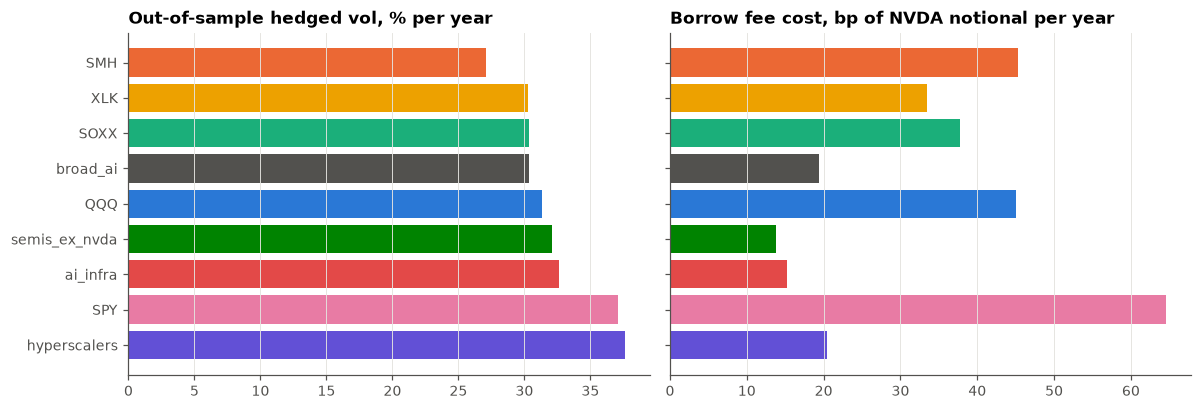

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
order = SUMMARY.index
axes[0].barh(order, SUMMARY["hedged vol OOS %"], color=[COLOR[h] for h in order])
axes[0].set_title("Out-of-sample hedged vol, % per year")
axes[1].barh(order, -SUMMARY["borrow cost (bp of L)"], color=[COLOR[h] for h in order])
axes[1].set_title("Borrow fee cost, bp of NVDA notional per year")
for ax in axes:
    ax.grid(axis="y", visible=False)
axes[0].invert_yaxis()
fig.tight_layout()
save(fig, "02_summary_vol_and_cost")

Cumulative net excess return of each hedged book (beta rule, out of sample, net of
borrow fees and financing), per \$1 of NVDA. This is a preview of the total return
series in step 3.

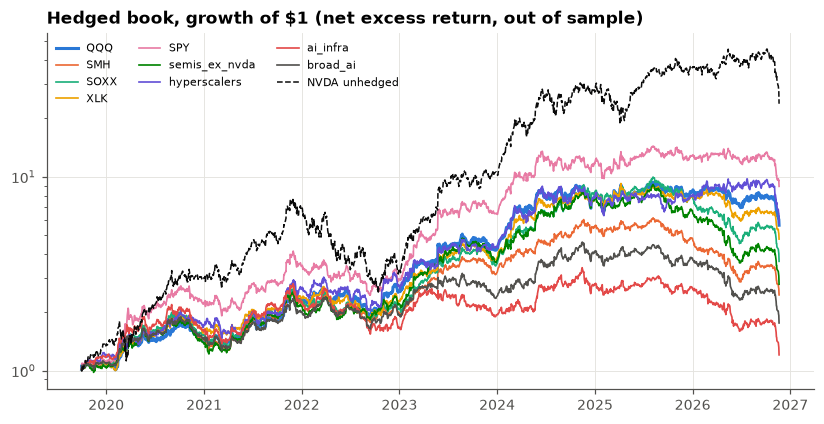

In [19]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for h in HEDGES:
    g = (1 + U[(h, "beta")].fillna(0)).cumprod()
    ax.plot(g.index, g, color=COLOR[h], lw=2 if h == "QQQ" else 1.1, label=h)
g0 = (1 + unhedged.fillna(0)).cumprod()
ax.plot(g0.index, g0, color=INK, lw=1, ls="--", label="NVDA unhedged")
ax.set_yscale("log")
ax.set_title("Hedged book, growth of $1 (net excess return, out of sample)")
ax.legend(ncol=3, fontsize=7, loc="upper left")
save(fig, "02_hedged_book_growth")

## Takeaways (data through 2026-11-20)

- **QQQ beta:** 1.66 over the full sample but 1.28 on the trailing 252 days (EWMA
  1.32). Every AI hedge's beta has fallen sharply in 2026. The semis ETFs and stock
  baskets are now at 0.45-0.67, about half their history, as NVDA has traded more on
  its own news. A full-sample ratio would over-hedge today.
- **Risk reduction:** hedging cuts NVDA's ~51% vol to about 27-37% out of sample. SMH
  leaves the least (27%), then XLK, SOXX and broad_ai (~30%), then QQQ (31%). SPY and
  the hyperscalers are the weakest hedges (~37%). R² never tops 0.7, so most of NVDA's
  risk is idiosyncratic and no basket makes this book "AI neutral" in a tight sense.
- **Rules:** the trailing-beta hedge beats dollar-neutral for every hedge. The
  multi-name minimum-variance hedge barely helps (semis_ex_nvda 31.4% vs 32.1%) and
  hurts for the hyperscalers: estimation noise eats the gain.
- **Asynchronous trading** is not an issue: weekly and daily betas match within about
  0.05, even for the basket with the TSM and ASML ADRs.
- **NVDA inside the ETFs** adds only about 0.06-0.10 to the full-sample beta, but it
  lowers R² by 7-13 points versus the ex-NVDA version. Shorting the current hedge
  ratio of SMH or XLK also shorts about 13-15% of the NVDA long.
- **Sizing (QQQ):** \$10k 1-day 99% VaR supports about \$230k NVDA long / \$294k QQQ
  short on trailing-252d vol, \$192-217k on historical VaR, and only \$145k on EWMA vol
  (vol has just jumped with NVDA's -14% day on 2026-11-20). At the \$230k size, the
  worst day (DeepSeek, 2025-01-27) loses about \$31k (3x the VaR) and the maximum
  drawdown is about \$104k.
- **Capital:** Reg T needs about \$262k (50% of each leg). Portfolio margin at ~15% a
  leg needs about \$79k. The \$294k of short proceeds plus \$147k of your margin sit in
  the short account and fund nothing.
- **Carry is about the cash balance, not the borrow fee.** Net carry is about
  `rf * (S - L)` plus small fee and dividend terms. QQQ's h > 1 earns a small positive
  carry (+\$1k/yr) with full rebate, but **about -\$11k/yr if the broker pays no
  rebate.** Borrow fees cost about 14-65 bp of the NVDA notional a year. The ETF fees
  (QQQ 35 bp, SMH 68 bp, SOXX 75 bp now) are lower than their history, and a smaller h
  offsets the higher semis-ETF fees.
- **Best after costs:** SMH has the lowest out-of-sample residual vol (27%) for about
  45 bp a year of borrow, the same cost as QQQ for 4 points less vol. broad_ai is the
  cheapest decent hedge (30% vol, 19 bp) but means running 18 shorts.